# Midterm research: a preliminary context/history forecaster

This is **HeTCo-v0**, a project-defined feature-based prototype on a fixed Independent Leiden/GED reference, not full heterogeneous/temporal/consensus detection. All 2015 data were inspected. Negative results, zero-support classes and unresolved transitions are retained. The three original pair demos remain separate.

Run the research command documented in `docs/RUNBOOK.md` first. This notebook reads verified artifacts; it never silently retrains or discovers a different run.

In [1]:
# Select the repository and run explicitly. Set these variables when launching
# Jupyter from another directory; selecting a Python kernel alone does not set cwd.
import os
from pathlib import Path
import sys
ROOT = Path(os.environ.get("REDDIT_SNA_PROJECT", Path.cwd())).resolve()
RUN = Path(os.environ.get("REDDIT_RESEARCH_RUN", ROOT / "artifacts/research/midterm-context-003")).resolve()
assert (ROOT / "pyproject.toml").is_file(), "Set REDDIT_SNA_PROJECT to the repository root"
assert RUN.is_relative_to(ROOT / "artifacts"), "Select a project artifact run"
print("Interpreter:", sys.executable)
print("Run:", RUN)
from reddit_sna.reporting.research import read_research, build_figures
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")  # Render images even if the launcher uses Agg.
import matplotlib.pyplot as plt

plt.ioff()  # Explicit display avoids duplicate automatic figures.


Interpreter: <PROJECT_ROOT>\.venv\Scripts\python.exe
Run: <PROJECT_ROOT>\artifacts\research\midterm-context-003


In [2]:
# The consumer checks file hashes, full sample/model/split keys, fit schedules,
# frozen protocol and metrics recomputed from predictions. It never unpickles.
delivery = read_research(RUN)
p = delivery["protocol"]
print("Status:", delivery["manifest"]["status"])
print("Protocol:", p["protocol_id"], "seeds:", p["seeds"])
print("Eligible samples:", len(delivery["samples"]))
print("Excluded transitions:", delivery["quality"]["unresolved"])
print("Exposure: inspected development data; human annotation pending; novelty unverified")


Status: complete
Protocol: midterm-context-history-v1 seeds: [42, 43, 44]
Eligible samples: 1333
Excluded transitions: 732
Exposure: inspected development data; human annotation pending; novelty unverified


## Experimental plan and population

Each community at month t is predicted at t+1. S contains five structural features; H contains seven past-only history attributes; L contains accepted-predecessor structure/missing flags; C summarizes within-month corpus/thread context. No complete-future-thread participant counts are allowed. B5 and proposed use identical boosting parameters and sample/label/reference keys. A1 removes C, A4 removes membership dynamics, and A6 removes L.

Main label-month holdout starts in October 2015. Rolling diagnostics refit on earlier label months for July–December. Three model seeds are repeats, not independent test months.

{
  "schema_version": 1,
  "protocol_id": "midterm-context-history-v1",
  "exposure": "inspected_development_data",
  "test_start": "2015-10",
  "seeds": [
    42,
    43,
    44
  ],
  "rolling_months": [
    "2015-07",
    "2015-08",
    "2015-09",
    "2015-10",
    "2015-11",
    "2015-12"
  ],
  "bootstrap": {
    "block_length": 2,
    "draws": 1000,
    "seed": 2026,
    "minimum_months": 6
  },
  "hgb": {
    "learning_rate": 0.05,
    "max_iter": 100,
    "max_depth": 3,
    "max_leaf_nodes": 7,
    "min_samples_leaf": 20,
    "l2_regularization": 1.0,
    "early_stopping": false,
    "class_weight": "balanced"
  },
  "rf": {
    "n_estimators": 100,
    "max_depth": 6,
    "min_samples_leaf": 5,
    "class_weight": "balanced",
    "n_jobs": 1
  },
  "lr": {
    "C": 1.0,
    "max_iter": 2000
  }
}


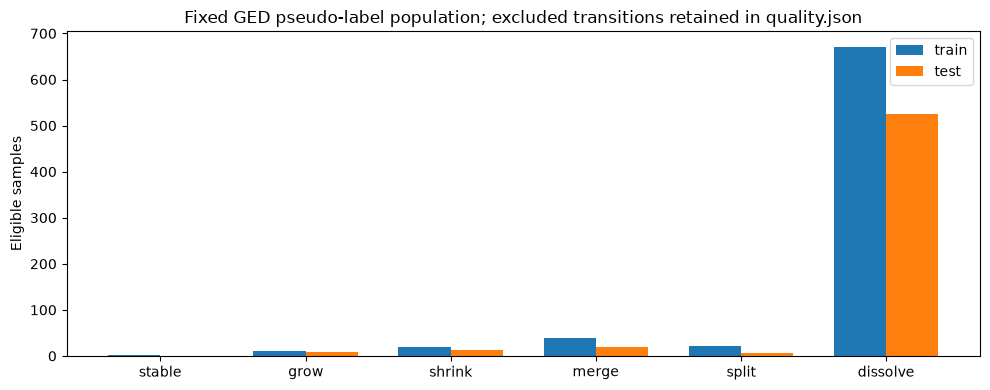

In [3]:
# Inspect the actual fixed settings before viewing any performance.
import json
print(json.dumps(p, indent=2))
figures = build_figures(delivery)
display(figures["population"])


## Baseline, proposed and ablation results

A preliminary method can fail to improve; completion does not require a positive delta. A1 and B5 must give identical predictions. A change of target labels is not evidence of better forecasting.

| Model | Six-class macro-F1 | Delta vs B5 | Samples/seed |
|---|---:|---:|---:|
| B1_majority | 0.159672 | -0.129341 | 571 |
| B1_persistence | 0.157730 | -0.131283 | 571 |
| B4_logreg | 0.360540 | +0.071528 | 571 |
| B2_random_forest | 0.305448 | +0.016435 | 571 |
| B5_matched_boosting | 0.289013 | +0.000000 | 571 |
| HeTCo_v0 | 0.291182 | +0.002170 | 571 |
| A1_no_context | 0.289013 | +0.000000 | 571 |
| A4_no_dynamics | 0.288225 | -0.000788 | 571 |
| A6_no_lag | 0.298036 | +0.009023 | 571 |

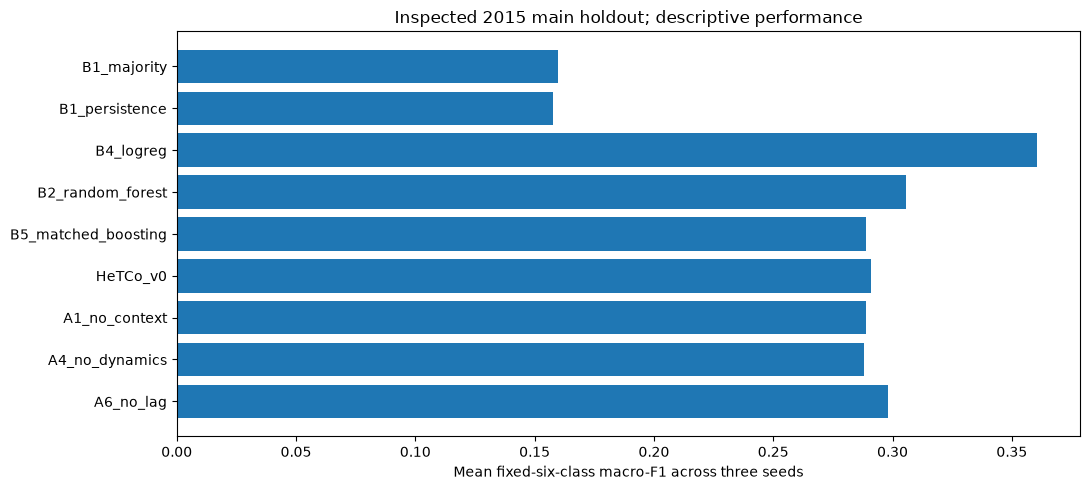

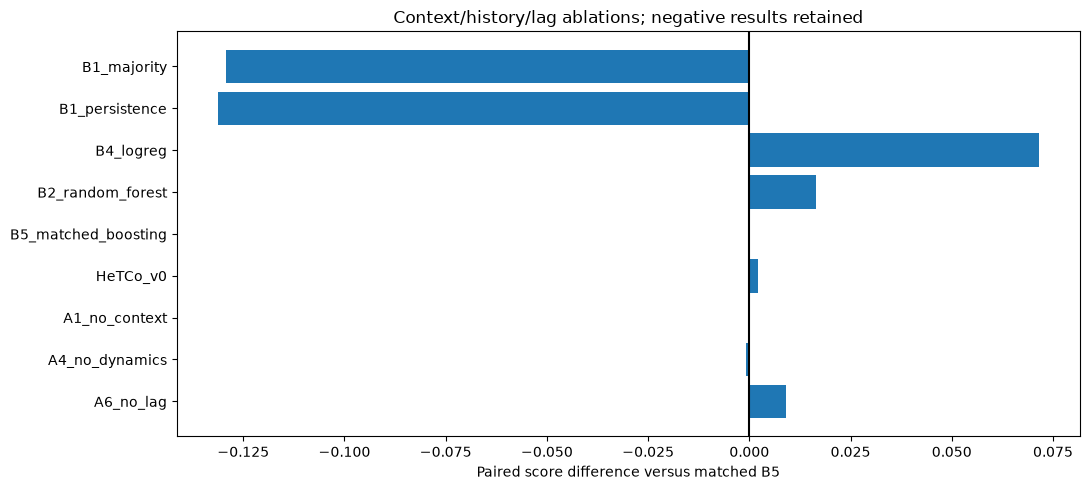

In [4]:
# Values below come exclusively from independently verified prediction files.
rows = [r for r in delivery["evaluation"]["means"] if r["window"] == "main"]
text = "| Model | Six-class macro-F1 | Delta vs B5 | Samples/seed |\n|---|---:|---:|---:|\n"
text += "\n".join(f"| {r['model']} | {r['mean_macro_f1_six']:.6f} | {r['delta_vs_B5']:+.6f} | {r['n_per_seed']} |" for r in rows)
display(Markdown(text))
display(figures["comparison"])
display(figures["ablations"])


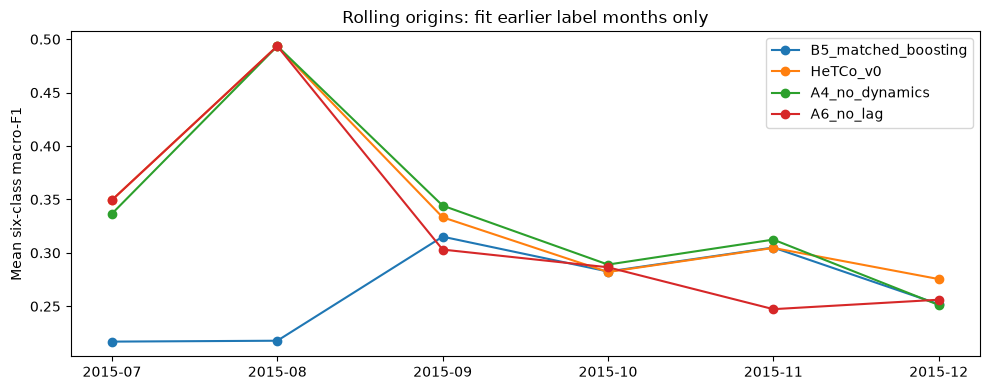

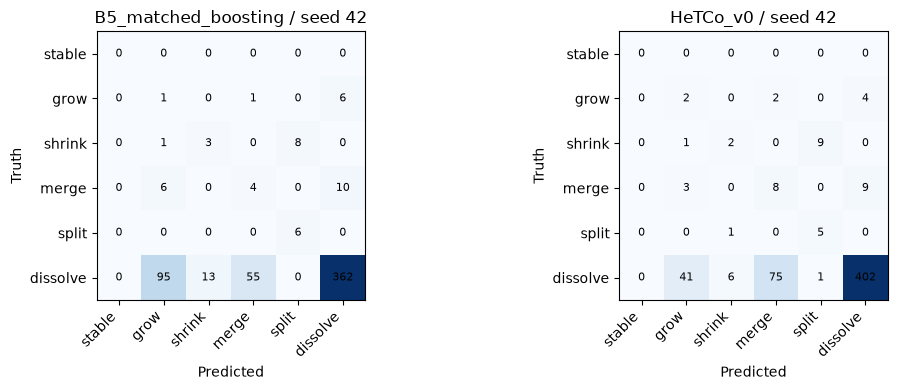

{
  "stable": {
    "precision": 0.0,
    "recall": 0.0,
    "f1": 0.0,
    "support": 0
  },
  "grow": {
    "precision": 0.0425531914893617,
    "recall": 0.25,
    "f1": 0.07272727272727272,
    "support": 8
  },
  "shrink": {
    "precision": 0.2222222222222222,
    "recall": 0.16666666666666666,
    "f1": 0.1904761904761905,
    "support": 12
  },
  "merge": {
    "precision": 0.09411764705882353,
    "recall": 0.4,
    "f1": 0.1523809523809524,
    "support": 20
  },
  "split": {
    "precision": 0.3333333333333333,
    "recall": 0.8333333333333334,
    "f1": 0.47619047619047616,
    "support": 6
  },
  "dissolve": {
    "precision": 0.9686746987951808,
    "recall": 0.7657142857142857,
    "f1": 0.8553191489361702,
    "support": 525
  }
}


In [5]:
# Track performance over time and retain class support/errors.
display(figures["monthly"])
display(figures["confusion"])
for row in delivery["evaluation"]["scores"]:
    if row["window"] == "main" and row["seed"] == 42 and row["model"] == "HeTCo_v0":
        print(json.dumps(row["per_class"], indent=2))


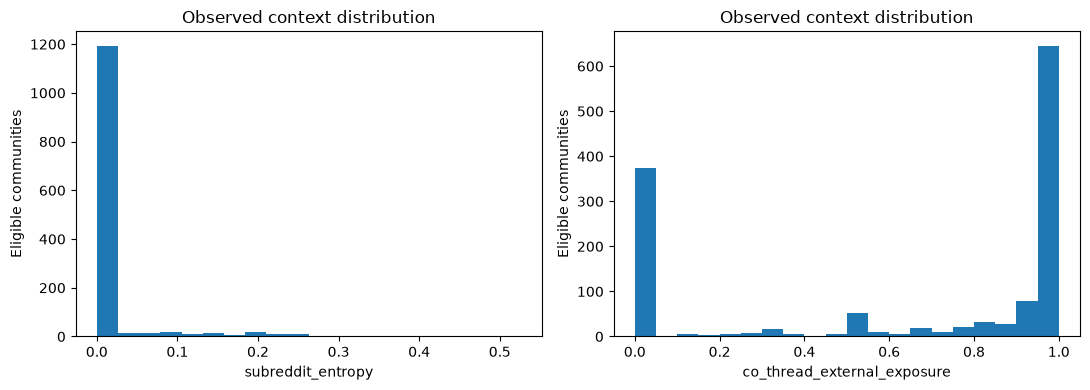

Recorded fit count: 189
Native peak memory: None
native peak process memory not measured


In [6]:
# Context distributions can expose degenerate or sparse explanatory variables.
display(figures["context"])
print("Recorded fit count:", len(delivery["fits"]))
print("Native peak memory:", delivery["manifest"]["native_peak_memory_mb"])
print(delivery["manifest"]["memory_reason"])


## Uncertainty and interpretation limits

No interval is reported for the three-month primary holdout. The six-month moving-block exercise uses paired month blocks of length 2 and 1,000 resamples; seed scores are averaged inside each resample. It is exploratory, with limited time support, and cannot establish H3 or unseen generalization.

Human review, closest-work novelty, full T/temporal/consensus detection and a confirmed untouched period remain separate obligations. Synthetic harder-regime findings are in the group report and their own verified run.

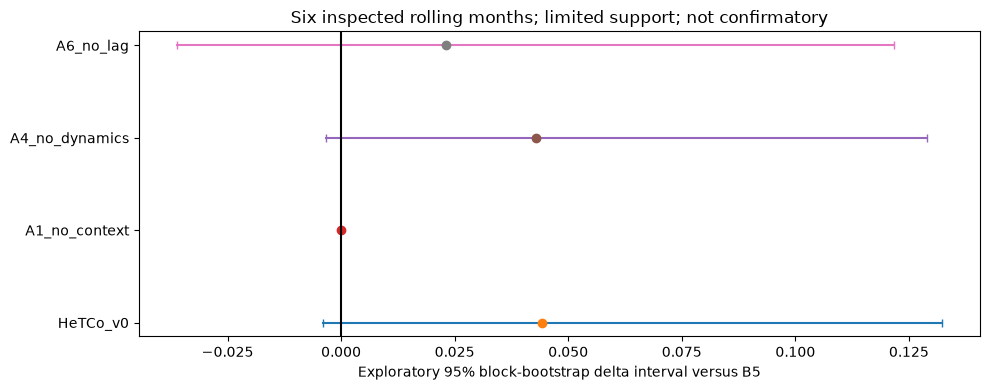

{
  "status": "exploratory_only",
  "main_holdout": {
    "status": "unavailable",
    "reason": "three inspected holdout months are insufficient for the six-month block policy"
  },
  "rolling_months": [
    "2015-07",
    "2015-08",
    "2015-09",
    "2015-10",
    "2015-11",
    "2015-12"
  ],
  "block_length": 2,
  "draws": 1000,
  "seed": 2026,
  "minimum_months": 6,
  "intervals": {
    "B1_majority": {
      "low": -0.14153407658924072,
      "high": -0.08304594613181815
    },
    "B1_persistence": {
      "low": -0.14388498985258663,
      "high": -0.08553476772834429
    },
    "B4_logreg": {
      "low": 0.06772180217428958,
      "high": 0.15613428021700107
    },
    "B2_random_forest": {
      "low": -0.0009902742362216665,
      "high": 0.06571322125601489
    },
    "B5_matched_boosting": {
      "low": 0.0,
      "high": 0.0
    },
    "HeTCo_v0": {
      "low": -0.004065638863624654,
      "high": 0.13222920445818867
    },
    "A1_no_context": {
      "low": 0.0,
  

In [7]:
display(figures["uncertainty"])
print(json.dumps(delivery["evaluation"]["uncertainty"], indent=2))
# Close figures after display; notebook output retains the actual rendered images.
for figure in figures.values():
    plt.close(figure)
